# 08 — Prophet forecasting of the aggregate series (Phase 3 · Step 3)

This notebook fits **Prophet** — an additive time-series model with a piecewise-linear trend, Fourier-series seasonality and
optional calendar regressors — to the one *aggregate* series of the project: the daily total of unit sales of store CA_1,
department FOODS_3 (823 products added together). It uses the **same five expanding development folds, the same 28-day horizon
and the same metrics** as the Phase 2 classical models and compares Prophet with them using their *saved* forecasts.

* **Aggregate series only.** Prophet is evaluated here on the aggregate series, **not** automatically on the intermittent
  item-level series (many zero days; handled by notebooks 05 and 06). Aggregate errors and item-level errors are on different
  scales and are never ranked against each other.
* **Final holdout.** The last 28 days (2016-04-25 → 2016-05-22) are reserved for one final evaluation and are **not read, fitted
  on, tuned on or reported** in this notebook (Section 6 checks the saved files).
* **No tuning.** Every setting comes from `config.yaml` (section `prophet`) and was fixed before any result existed; the three
  variants (additive, multiplicative, additive without regressors) are pre-declared there too.

## 1. Objective

*How does Prophet — a trend + seasonality + events model — compare with the Phase 2 classical models (Seasonal Naive, ARIMA,
SARIMA, Holt-Winters) when everything is evaluated the same way, and do its calendar regressors help?*

The notebook measures **MAE, RMSE, zero-protected MAPE, WAPE and MASE per fold, their mean and their variation across folds**,
checks how well Prophet's 80 % uncertainty interval covers the actual sales, and reports every fit's convergence status.
It does not claim a universal winner (Section 9).

## 2. Method — what Prophet does

Prophet models the daily series as a sum of parts:

**y(t) = trend(t) + weekly(t) + yearly(t) + events(t) + noise**

* **Trend** — a straight line whose slope may change at a number of **changepoints** (25 candidates spread over the first 80 %
  of the history here). A *prior* (`changepoint_prior_scale = 0.05`) keeps most slope changes near zero unless the data insist:
  larger values make the trend more flexible.
* **Seasonality** — smooth repeating patterns written as Fourier series: a **weekly** pattern (weekday effects) and a **yearly**
  pattern (summer, winter holidays). Daily seasonality is off (the data are already daily).
* **Events / regressors** — extra columns whose effect is learned. Here they are calendar *facts published in advance*:
  **SNAP-benefit days** (California), the four **M5 event types** (cultural, national, religious, sporting) and the
  **Christmas closure** (the stores report zero sales on 25 December). They are known for the 28 future days too, so using them
  does not peek at the future — no sales value is ever used as a future input.
* **Additive vs multiplicative.** In *additive* mode seasonal and event effects are added to the trend (±300 units); in
  *multiplicative* mode they scale it (±8 %). When sales grow, the multiplicative form lets the weekly swing grow with them.
* **Estimation.** Prophet is a Bayesian model fitted in Stan. Here it is fitted by **MAP** (maximum a posteriori: the single most
  probable parameter set, found by an optimiser), which is fast and gives a deterministic point forecast. Full MCMC is not used.
* **Uncertainty interval.** Prophet simulates 1,000 futures (random future slope changes + observation noise) and reports the
  10th and 90th percentile — an **80 % interval** (`interval_width = 0.8`). The simulation is seeded, so it is reproducible.
* **Non-negativity.** Forecasts and interval bounds are clipped at zero (`max(x, 0)`); the number of clipped values is reported.

| Variant (pre-declared) | Seasonality | Calendar regressors | Information set |
|---|---|---|---|
| `Prophet(additive)` — primary | additive | yes | history + calendar facts |
| `Prophet(multiplicative)` | multiplicative | yes | history + calendar facts |
| `Prophet(additive,no-regressors)` | additive | no | history only (same as the Phase 2 models) |

**Dependencies.** `python -m pip install prophet` (or `python -m pip install -r requirements-phase3.txt`). The wheel bundles the
Stan backend, so no compiler is needed. On Windows the Stan executable can fail to start if the project/venv path contains
spaces; if that happens the error message says what to do and **no other method is substituted**.

## 3. Setup and reproducibility

Run from the project root with
`python -m jupyter nbconvert --to notebook --execute --inplace notebooks/08_prophet.ipynb` (a few minutes), or open the
notebook in VS Code / Jupyter and run all cells.

In [1]:
import sys
from pathlib import Path


def _find_project_root(start: Path) -> Path:
    """Walk up from `start` until a directory containing config.yaml is found."""
    for candidate in [start, *start.parents]:
        if (candidate / "config.yaml").exists():
            return candidate
    raise FileNotFoundError(
        f"Could not find config.yaml in any parent directory of '{start}'. Run this notebook from within the project."
    )


PROJECT_ROOT = _find_project_root(Path.cwd())
sys.path.insert(0, str(PROJECT_ROOT))

import logging
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.data.aggregate_series import load_aggregate_development
from src.evaluation.backtesting import run_backtest, summarize_backtest
from src.evaluation.forecast_artifacts import (
    audit_forecast_table,
    backtest_results_to_forecast_table,
    expected_fold_windows,
    fold_training_scales,
    load_aggregate_forecast_tables,
    metrics_by_group,
    read_forecast_table,
    write_forecast_table,
)
from src.models.prophet_model import (
    ProphetForecaster,
    ProphetSettings,
    build_future_frame,
    build_training_frame,
    future_dates,
    primary_variant_name,
    variants_from_config,
)
from src.models.xgboost_model import EVENT_FLAG_COLUMNS, load_event_calendar
from src.utils.config import load_config
from src.utils.provenance import build_run_metadata, library_versions, write_json

try:
    import prophet
except ImportError as exc:  # a clear message instead of a stack trace
    raise ImportError(
        "This notebook needs Prophet. Install it with:  python -m pip install prophet  "
        "(or: python -m pip install -r requirements-phase3.txt)"
    ) from exc

warnings.filterwarnings("ignore")
logging.getLogger().setLevel(logging.WARNING)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)
plt.rcParams.update({"figure.dpi": 100, "font.size": 10, "axes.grid": True, "grid.alpha": 0.3})

config = load_config()
versions = library_versions(["prophet", "cmdstanpy", "pandas", "numpy"])
print("Python", sys.version.split()[0], "| pandas", pd.__version__, "| numpy", np.__version__, "| prophet", prophet.__version__, "| cmdstanpy", versions["cmdstanpy"])
print("Backtest settings:", config["backtest"])
print("Prophet settings :", {k: v for k, v in config["prophet"].items() if k not in ("variants", "regressors")})
print("Regressors       :", config["prophet"]["regressors"])

Python 3.13.16 | pandas 3.0.5 | numpy 2.5.3 | prophet 1.5.0 | cmdstanpy 1.3.0
Backtest settings: {'holdout_days': 28, 'horizon': 28, 'n_folds': 5, 'season_length': 7}
Prophet settings : {'yearly_seasonality': True, 'weekly_seasonality': True, 'daily_seasonality': False, 'changepoint_prior_scale': 0.05, 'seasonality_prior_scale': 10.0, 'n_changepoints': 25, 'changepoint_range': 0.8, 'interval_width': 0.8, 'mcmc_samples': 0, 'uncertainty_samples': 1000, 'random_seed': 42, 'primary_variant': 'Prophet(additive)'}
Regressors       : ['snap_ca', 'event_cultural', 'event_national', 'event_religious', 'event_sporting', 'is_christmas']


In [2]:
forecasts_dir = PROJECT_ROOT / config["phase3"]["forecasts_dir"]
metrics_dir = PROJECT_ROOT / config["phase3"]["metrics_dir"]
reports_dir = PROJECT_ROOT / config["reports"]["phase3_dir"]
for directory in (forecasts_dir, metrics_dir, reports_dir):
    directory.mkdir(parents=True, exist_ok=True)
p3 = config["phase3"]

# The ONLY way this notebook gets the series: the development period, holdout already cut off.
series, window = load_aggregate_development(config)
HORIZON, N_FOLDS = config["backtest"]["horizon"], config["backtest"]["n_folds"]
print(f"Development series: {len(series)} days, {series.index[0].date()} -> {series.index[-1].date()}  (aggregate daily unit sales)")
print(f"Reserved final holdout: {window.holdout_start.date()} -> {window.holdout_end.date()} ({window.n_holdout_days} days) -- dates only; its values are not loaded here.")

windows = expected_fold_windows(series.index, HORIZON, N_FOLDS)
print("\nThe five expanding development folds (identical to Phase 2):")
print(windows.assign(**{c: windows[c].dt.date for c in ("origin_date", "forecast_start", "forecast_end")}).to_string(index=False))

panel_path = PROJECT_ROOT / config["data"]["interim_dir"] / config["output"]["panel_filename"]
calendar = load_event_calendar(panel_path, last_date=window.dev_end)       # calendar columns only; read-time date filter
print(f"\nEvent calendar: {len(calendar)} days, {calendar.index.min().date()} -> {calendar.index.max().date()}")
print("Days flagged per regressor over the development period:", calendar.sum().astype(int).to_dict())
assert calendar.index.max() <= window.dev_end

settings = ProphetSettings.from_config(config)
VARIANTS = variants_from_config(config)
PRIMARY = primary_variant_name(config)
assert len(VARIANTS) == 3
print("\nPre-declared variants:", [v.name for v in VARIANTS], "| primary:", PRIMARY)

Development series: 1913 days, 2011-01-29 -> 2016-04-24  (aggregate daily unit sales)
Reserved final holdout: 2016-04-25 -> 2016-05-22 (28 days) -- dates only; its values are not loaded here.

The five expanding development folds (identical to Phase 2):
 fold  n_train origin_date forecast_start forecast_end
    1     1773  2015-12-06     2015-12-07   2016-01-03
    2     1801  2016-01-03     2016-01-04   2016-01-31
    3     1829  2016-01-31     2016-02-01   2016-02-28
    4     1857  2016-02-28     2016-02-29   2016-03-27
    5     1885  2016-03-27     2016-03-28   2016-04-24



Event calendar: 1913 days, 2011-01-29 -> 2016-04-24
Days flagged per regressor over the development period: {'snap_ca': 630, 'event_cultural': 38, 'event_national': 51, 'event_religious': 53, 'event_sporting': 16, 'is_christmas': 5}

Pre-declared variants: ['Prophet(additive)', 'Prophet(multiplicative)', 'Prophet(additive,no-regressors)'] | primary: Prophet(additive)


## 4. Leakage and alignment check on real dates

Prophet is asked for a *future* it has never seen, so this section makes explicit what is — and is not — given to it, using
fold 5's real dates.

In [3]:
fold = N_FOLDS
row = windows.loc[windows["fold"] == fold].iloc[0]
history = series.iloc[: int(row.n_train)]
regressors = settings.regressors

training_frame = build_training_frame(history, calendar, regressors)
future_frame = build_future_frame(history.index[-1], HORIZON, calendar, regressors)
print(f"Fold {fold}: training frame  {training_frame['ds'].iloc[0].date()} -> {training_frame['ds'].iloc[-1].date()}  columns {list(training_frame.columns)}")
print(f"        future frame    {future_frame['ds'].iloc[0].date()} -> {future_frame['ds'].iloc[-1].date()}  columns {list(future_frame.columns)}")
assert training_frame["ds"].iloc[-1] == history.index[-1] < row.forecast_start
assert future_frame["ds"].iloc[0] == row.forecast_start and future_frame["ds"].iloc[-1] == row.forecast_end
assert "y" not in future_frame.columns, "the future frame must not carry sales"
assert future_dates(history.index[-1], HORIZON).equals(pd.DatetimeIndex(future_frame["ds"]))
print("The future frame holds ONLY the forecast dates (generated from the last history date) and calendar flags -- no `y` column, no sales.")

# 1) Changing every sales value after the origin changes nothing: they are never passed to the model.
primary_variant = next(v for v in VARIANTS if v.name == PRIMARY)
reference = ProphetForecaster(primary_variant, settings, calendar=calendar).fit(history).predict(HORIZON)
tampered = series.copy()
tampered.iloc[int(row.n_train):] = 1_000_000.0
again = ProphetForecaster(primary_variant, settings, calendar=calendar).fit(tampered.iloc[: int(row.n_train)]).predict(HORIZON)
assert np.array_equal(reference, again)
print("Perturbation test passed: setting every sales value after the origin to 1,000,000 leaves the forecast bit-identical.")

# 2) The calendar is the ONLY information about the future days, and the regressor variants really use it.
flipped = calendar.copy()
flipped.loc[future_frame["ds"], "snap_ca"] = 1 - flipped.loc[future_frame["ds"], "snap_ca"]
changed = ProphetForecaster(primary_variant, settings, calendar=flipped).fit(history).predict(HORIZON)
print(f"Flipping the SNAP flag on the 28 forecast days changes the {PRIMARY} forecast by up to {np.abs(changed - reference).max():.1f} units/day "
      "(so the regressor is used), while the history-only variant ignores the calendar entirely.")
assert not np.allclose(changed, reference)

# 3) Missing calendar dates are never zero-filled.
try:
    ProphetForecaster(primary_variant, settings, calendar=calendar.loc[: history.index[-1]]).fit(history)
except ValueError as error:
    print("A calendar that stops at the origin is refused:", str(error)[:110], "...")

Fold 5: training frame  2011-01-29 -> 2016-03-27  columns ['ds', 'y', 'snap_ca', 'event_cultural', 'event_national', 'event_religious', 'event_sporting', 'is_christmas']
        future frame    2016-03-28 -> 2016-04-24  columns ['ds', 'snap_ca', 'event_cultural', 'event_national', 'event_religious', 'event_sporting', 'is_christmas']
The future frame holds ONLY the forecast dates (generated from the last history date) and calendar flags -- no `y` column, no sales.


Perturbation test passed: setting every sales value after the origin to 1,000,000 leaves the forecast bit-identical.


Flipping the SNAP flag on the 28 forecast days changes the Prophet(additive) forecast by up to 224.2 units/day (so the regressor is used), while the history-only variant ignores the calendar entirely.
A calendar that stops at the origin is refused: The event calendar does not cover 28 requested date(s) (first: 2016-03-28). Missing dates are never filled wit ...


## 5. The experiment: 3 variants × 5 folds

Each variant goes through the project's own `run_backtest` loop (a fresh model per fold, fitted on that fold's training prefix
only). A fit that fails is *recorded* with its error — never dropped and never replaced by another method.

In [4]:
runs = {}
for variant in VARIANTS:
    instances = []

    def factory(variant=variant, instances=instances):
        model = ProphetForecaster.from_config(variant.name, config, calendar=calendar)
        instances.append(model)
        return model

    started = time.perf_counter()
    results = run_backtest(series, factory, horizon=HORIZON, n_folds=N_FOLDS)
    seconds = time.perf_counter() - started
    runs[variant.name] = {"results": results, "instances": instances, "seconds": seconds}
    ok = [r for r in results if r.success]
    converged = sum(bool(r.diagnostics.get("optimizer_converged")) for r in ok)
    print(f"{variant.name:34s} folds ok {len(ok)}/{len(results)} | optimiser converged {converged}/{len(ok)} | {seconds:5.1f} s")
    for r in results:
        if not r.success:
            print(f"   FAILED fold {r.fold}: {r.error}")

Prophet(additive)                  folds ok 5/5 | optimiser converged 5/5 |   3.0 s


Prophet(multiplicative)            folds ok 5/5 | optimiser converged 5/5 |   3.6 s


Prophet(additive,no-regressors)    folds ok 5/5 | optimiser converged 5/5 |   3.4 s


### 5.1 Assembling and saving the artifacts

In [5]:
forecast_frames, metric_frames, diagnostic_rows = [], [], []
for name, run in runs.items():
    table = backtest_results_to_forecast_table(run["results"])
    lower, upper = [], []
    for result, model in zip(run["results"], run["instances"]):
        if result.success:
            low, high = model.predict_interval(HORIZON)
            lower.extend(low.tolist())
            upper.extend(high.tolist())
            d = result.diagnostics
            diagnostic_rows.append({
                "model": name, "fold": result.fold, "n_obs": d["n_obs"], "history_end": d["history_end"],
                "seasonality_mode": d["seasonality_mode"], "uses_regressors": d["uses_regressors"],
                "n_changepoints_fitted": d["n_changepoints_fitted"], "optimizer_converged": d["optimizer_converged"],
                "log_posterior": d["log_posterior"], "n_negative_values_clipped": d["n_negative_values_clipped"],
                "fit_seconds": d["fit_seconds"], "success": True, "error": None,
            })
        else:
            lower.extend([np.nan] * len(result.dates))
            upper.extend([np.nan] * len(result.dates))
            diagnostic_rows.append({"model": name, "fold": result.fold, "success": False, "error": result.error})
    table["lower"], table["upper"] = lower, upper
    forecast_frames.append(table)
    metric_frames.append(summarize_backtest(run["results"]))

prophet_table = pd.concat(forecast_frames, ignore_index=True)
prophet_metrics = pd.concat(metric_frames, ignore_index=True)
prophet_diagnostics = pd.DataFrame(diagnostic_rows)

write_forecast_table(prophet_table, forecasts_dir / p3["prophet_forecasts_filename"])
prophet_metrics.to_csv(metrics_dir / p3["prophet_metrics_filename"], index=False, lineterminator="\n")
prophet_diagnostics.to_csv(metrics_dir / p3["prophet_diagnostics_filename"], index=False, lineterminator="\n")

total_seconds = sum(run["seconds"] for run in runs.values())
metadata = build_run_metadata(
    "prophet", config=config, config_keys=["prophet", "backtest"],
    extra={
        "variants": [v.name for v in VARIANTS], "primary_variant": PRIMARY, "folds": N_FOLDS, "horizon": HORIZON,
        "fits": int(len(prophet_diagnostics)), "failed_fits": int((~prophet_diagnostics["success"]).sum()),
        "non_converged_fits": int((prophet_diagnostics["optimizer_converged"] == False).sum()),  # noqa: E712
        "wall_seconds_total": round(total_seconds, 1), "wall_seconds_by_variant": {k: round(v["seconds"], 1) for k, v in runs.items()},
        "estimation": "MAP", "interval_width": settings.interval_width, "interval_seed": settings.random_seed,
        "development_end": str(window.dev_end.date()),
    },
)
write_json(metrics_dir / p3["prophet_metadata_filename"], metadata)

print(f"Forecast table : {len(prophet_table)} rows (with lower/upper) -> {p3['prophet_forecasts_filename']}")
print(f"Metrics table  : {len(prophet_metrics)} rows -> {p3['prophet_metrics_filename']}")
print(f"Fit diagnostics: {len(prophet_diagnostics)} fits -> {p3['prophet_diagnostics_filename']}")
print(f"Run metadata   : {p3['prophet_metadata_filename']}")
print(f"Total fitting time: {total_seconds:.0f} seconds for {len(prophet_diagnostics)} fits")

Forecast table : 420 rows (with lower/upper) -> prophet_backtest_forecasts.csv
Metrics table  : 15 rows -> prophet_backtest_metrics.csv
Fit diagnostics: 15 fits -> prophet_fit_diagnostics.csv
Run metadata   : prophet_run_metadata.json
Total fitting time: 10 seconds for 15 fits


## 6. Integrity checks

The saved forecast table passes the same audit as every forecast table in this project: same folds and forecast windows as the
protocol, actuals equal to the development series, finite and non-negative predictions, and **no date after the end of the
development period**.

In [6]:
saved = read_forecast_table(forecasts_dir / p3["prophet_forecasts_filename"], "aggregate")
checks = audit_forecast_table(saved, kind="aggregate", dev_series=series, horizon=HORIZON, n_folds=N_FOLDS)
for c in checks:
    print(("PASS" if c.passed else "FAIL"), "-", c.name, "-", c.detail)
assert all(c.passed for c in checks)

n_expected = len(VARIANTS) * N_FOLDS * HORIZON
print(f"\nRows in the saved table: {len(saved)} (expected {n_expected}); models: {sorted(saved['model'].unique())}")
print("Failed fits:", int((~prophet_diagnostics['success']).sum()), "of", len(prophet_diagnostics))
print("Optimiser did not report convergence:", int((prophet_diagnostics["optimizer_converged"] == False).sum()), "fit(s)")  # noqa: E712
print("Negative predictions in the saved table:", int((saved["predicted"] < 0).sum()), "| negative interval bounds:", int((saved[["lower", "upper"]] < 0).sum().sum()))
print("Rows where lower <= predicted <= upper does not hold:", int(((saved["lower"] > saved["predicted"] + 1e-9) | (saved["predicted"] > saved["upper"] + 1e-9)).sum()))
print("Forecast values changed by the clip-at-zero rule (point + both bounds, all fits):", int(prophet_diagnostics["n_negative_values_clipped"].fillna(0).sum()))
print(f"Latest forecast date saved: {saved['date'].max().date()}  |  last development day: {window.dev_end.date()}  |  holdout starts: {window.holdout_start.date()}")
assert saved["date"].max() <= window.dev_end
print("Confirmed: no date in the reserved final holdout appears in the saved forecasts.")

repeat = ProphetForecaster.from_config(PRIMARY, config, calendar=calendar).fit(series.iloc[: int(windows.n_train.iloc[-1])])
original = runs[PRIMARY]["instances"][-1]
assert np.array_equal(repeat.predict(HORIZON), original.predict(HORIZON))
assert all(np.array_equal(a, b) for a, b in zip(repeat.predict_interval(HORIZON), original.predict_interval(HORIZON)))
print(f"Determinism: re-fitting {PRIMARY} on fold {N_FOLDS} reproduces the point forecast AND the seeded interval bit for bit.")

PASS - no_dates_after_development_end - ok
PASS - no_duplicate_rows - 0 duplicated row(s)
PASS - folds_and_windows_match_protocol - ok
PASS - actuals_equal_development_series - ok
PASS - predictions_finite_on_successful_rows - 0 non-finite prediction(s)
PASS - predictions_non_negative - 0 negative prediction(s)

Rows in the saved table: 420 (expected 420); models: ['Prophet(additive)', 'Prophet(additive,no-regressors)', 'Prophet(multiplicative)']
Failed fits: 0 of 15
Optimiser did not report convergence: 0 fit(s)
Negative predictions in the saved table: 0 | negative interval bounds: 0
Rows where lower <= predicted <= upper does not hold: 0
Forecast values changed by the clip-at-zero rule (point + both bounds, all fits): 3
Latest forecast date saved: 2016-04-24  |  last development day: 2016-04-24  |  holdout starts: 2016-04-25
Confirmed: no date in the reserved final holdout appears in the saved forecasts.


Determinism: re-fitting Prophet(additive) on fold 5 reproduces the point forecast AND the seeded interval bit for bit.


## 7. Results

### 7.1 Metrics used
For actual sales *a* and forecast *f* over a fold's 28 forecast days:

* **MAE** = mean |a − f| and **RMSE** = √mean (a − f)² — in units/day of the aggregate series.
* **MAPE** = mean |a − f| / a **over days with a > 0**, in %. A day with zero actual sales (the Christmas closure is in fold 1) cannot
  be expressed as a percentage, so it is **excluded and counted** (`mape_n_excluded`); MAPE is a secondary metric.
* **WAPE** = Σ|a − f| / Σa (scale-free, defined whenever there is any demand).
* **MASE** = MAE / (mean |y_t − y_{t−7}| over the fold's *training* window): MAE relative to the in-sample error of a seasonal-naive
  forecast; below 1 means better than that in-sample benchmark. NaN if that scale is zero.
* Every figure is **recomputed from the saved (actual, predicted) pairs** with the project's own metric functions, and checked
  against the metrics file written above.

In [7]:
classical_names = [config["phase2"][k] for k in ("seasonal_naive_forecasts_filename", "arima_forecasts_filename",
                                                   "sarima_forecasts_filename", "holt_winters_forecasts_filename")]
classical_tables, problems = load_aggregate_forecast_tables(classical_names, config)
for filename, message in problems.items():
    print("MISSING / INVALID ARTIFACT:", message)
if problems:
    print("\nThe comparison below contains only the models whose artifacts exist; nothing is filled in for the others.")

scales = fold_training_scales(series, windows, lag=config["comparison"]["mase_seasonal_lag"])
scale_frame = pd.DataFrame({"fold": list(scales), "mase_scale": list(scales.values())})
classical_failures = {fn: [c.name for c in audit_forecast_table(t, kind="aggregate", dev_series=series) if not c.passed] for fn, t in classical_tables.items()}
print("Audit failures in the Phase 2 forecast files:", {k: v for k, v in classical_failures.items() if v} or "none")

combined = pd.concat(list(classical_tables.values()) + [saved.drop(columns=["lower", "upper"])], ignore_index=True)
fold_metrics = metrics_by_group(combined, ["model", "fold"], scale_frame)

check = fold_metrics[fold_metrics["model"].isin(prophet_metrics["model"])].merge(prophet_metrics, on=["model", "fold"], suffixes=("", "_saved"))
assert np.allclose(check["MAE"], check["MAE_saved"], atol=1e-8) and np.allclose(check["RMSE"], check["RMSE_saved"], atol=1e-8)
print("Recomputed Prophet MAE/RMSE equal the saved metrics file for every (model, fold).")

PROPHET_MODELS = list(prophet_metrics["model"].unique())
CLASSICAL = [m for m in fold_metrics["model"].unique() if m not in set(PROPHET_MODELS)]
print("Classical (Phase 2) models:", CLASSICAL)
print("Prophet variants          :", PROPHET_MODELS)

Audit failures in the Phase 2 forecast files: none
Recomputed Prophet MAE/RMSE equal the saved metrics file for every (model, fold).
Classical (Phase 2) models: ['SeasonalNaive', 'ARIMA(6, 1, 1)', 'SARIMA(6, 1, 1)x(0, 0, 2, 7)', 'HoltWinters(trend=add)']
Prophet variants          : ['Prophet(additive)', 'Prophet(multiplicative)', 'Prophet(additive,no-regressors)']


In [8]:
def fold_table(metric):
    pivot = fold_metrics.pivot(index="model", columns="fold", values=metric)
    spread = pivot.std(axis=1, ddof=1)
    pivot.columns = [f"fold {c}" for c in pivot.columns]
    pivot["mean"] = pivot.mean(axis=1)
    pivot["std (folds)"] = spread
    return pivot.reindex(CLASSICAL + PROPHET_MODELS)


print("MAE by fold (units/day, aggregate series) -- fixed row order: Phase 2 models, then the Prophet variants")
print(fold_table("MAE").round(1).to_string())
print("\nRMSE by fold (units/day)")
print(fold_table("RMSE").round(1).to_string())

summary = (
    fold_metrics.groupby("model")
    .agg(MAE_mean=("MAE", "mean"), MAE_std=("MAE", "std"), RMSE_mean=("RMSE", "mean"), RMSE_std=("RMSE", "std"),
         MAPE_mean_pct=("MAPE", "mean"), WAPE_mean=("WAPE", "mean"), MASE_mean=("MASE", "mean"), bias_mean=("bias", "mean"),
         folds_scored=("success", "sum"))
    .reindex(CLASSICAL + PROPHET_MODELS)
)
summary.insert(0, "family", ["classical (Phase 2)"] * len(CLASSICAL) + ["Prophet (this notebook)"] * len(PROPHET_MODELS))
summary["zero_days_excluded_from_MAPE"] = fold_metrics.groupby("model")["mape_n_excluded"].sum().reindex(summary.index)
print("\nMean over the five development folds (std = sample std across folds). The order is fixed, not a ranking.")
print(summary.round(3).to_string())
print("\nMAPE caveat: days with zero actual sales are excluded and counted above. bias = mean(forecast - actual); positive = over-forecast.")

MAE by fold (units/day, aggregate series) -- fixed row order: Phase 2 models, then the Prophet variants
                                 fold 1  fold 2  fold 3  fold 4  fold 5   mean  std (folds)
model                                                                                      
SeasonalNaive                     253.4   323.9   289.1   189.6   226.7  256.6         52.4
ARIMA(6, 1, 1)                    217.3   323.1   244.8   219.8   223.1  245.6         44.7
SARIMA(6, 1, 1)x(0, 0, 2, 7)      269.8   314.9   237.1   164.7   153.3  228.0         68.8
HoltWinters(trend=add)            270.1   249.6   167.3   143.5   136.2  193.3         62.2
Prophet(additive)                 271.8   170.4   255.8   231.5   181.6  222.2         44.7
Prophet(multiplicative)           268.0   173.1   268.6   246.1   184.5  228.0         46.1
Prophet(additive,no-regressors)   304.5   160.5   243.8   222.3   198.2  225.9         53.7

RMSE by fold (units/day)
                                 fold 1  f


Mean over the five development folds (std = sample std across folds). The order is fixed, not a ranking.


                                                  family  MAE_mean  MAE_std  RMSE_mean  RMSE_std  MAPE_mean_pct  WAPE_mean  MASE_mean  bias_mean  folds_scored  zero_days_excluded_from_MAPE
model                                                                                                                                                                                       
SeasonalNaive                        classical (Phase 2)   256.550   52.413    329.050    73.122         12.082      0.131      0.974    -79.179             5                             1
ARIMA(6, 1, 1)                       classical (Phase 2)   245.611   44.688    333.369    63.864         11.316      0.124      0.933    -45.591             5                             1
SARIMA(6, 1, 1)x(0, 0, 2, 7)         classical (Phase 2)   227.965   68.848    302.223    93.826         10.639      0.118      0.865    -86.529             5                             1
HoltWinters(trend=add)               classical (Phase 2

### 7.2 Uncertainty interval: does the 80 % interval cover about 80 % of the actual days?

In [9]:
inside = saved.assign(covered=(saved["actual"] >= saved["lower"]) & (saved["actual"] <= saved["upper"]),
                      width=saved["upper"] - saved["lower"])
coverage_by_fold = inside.groupby(["model", "fold"]).agg(coverage=("covered", "mean"), mean_width=("width", "mean")).reset_index()
coverage = inside.groupby("model").agg(coverage=("covered", "mean"), mean_width=("width", "mean"), days=("covered", "size"))
print(f"Nominal interval level: {settings.interval_width:.0%}. Empirical coverage = share of forecast days whose ACTUAL value lay inside [lower, upper].")
print(coverage.round(3).to_string())
print("\nCoverage by fold:")
print(coverage_by_fold.pivot(index="model", columns="fold", values="coverage").round(3).to_string())
standard_error = np.sqrt(settings.interval_width * (1 - settings.interval_width) / (N_FOLDS * HORIZON))
print(f"\nCaveat: {N_FOLDS * HORIZON} forecast days per variant (consecutive days are correlated) give a coverage estimate with a standard error of "
      f"at least about {standard_error:.1%}; a single fold of {HORIZON} days is much coarser. These are descriptions, not a calibration test.")

Nominal interval level: 80%. Empirical coverage = share of forecast days whose ACTUAL value lay inside [lower, upper].
                                 coverage  mean_width  days
model                                                      
Prophet(additive)                   0.750     585.306   140
Prophet(additive,no-regressors)     0.814     711.581   140
Prophet(multiplicative)             0.729     564.533   140

Coverage by fold:


fold                                 1      2      3      4      5
model                                                             
Prophet(additive)                0.679  0.821  0.607  0.714  0.929
Prophet(additive,no-regressors)  0.714  0.857  0.750  0.857  0.893
Prophet(multiplicative)          0.679  0.821  0.571  0.679  0.893

Caveat: 140 forecast days per variant (consecutive days are correlated) give a coverage estimate with a standard error of at least about 3.4%; a single fold of 28 days is much coarser. These are descriptions, not a calibration test.


### 7.3 Figures

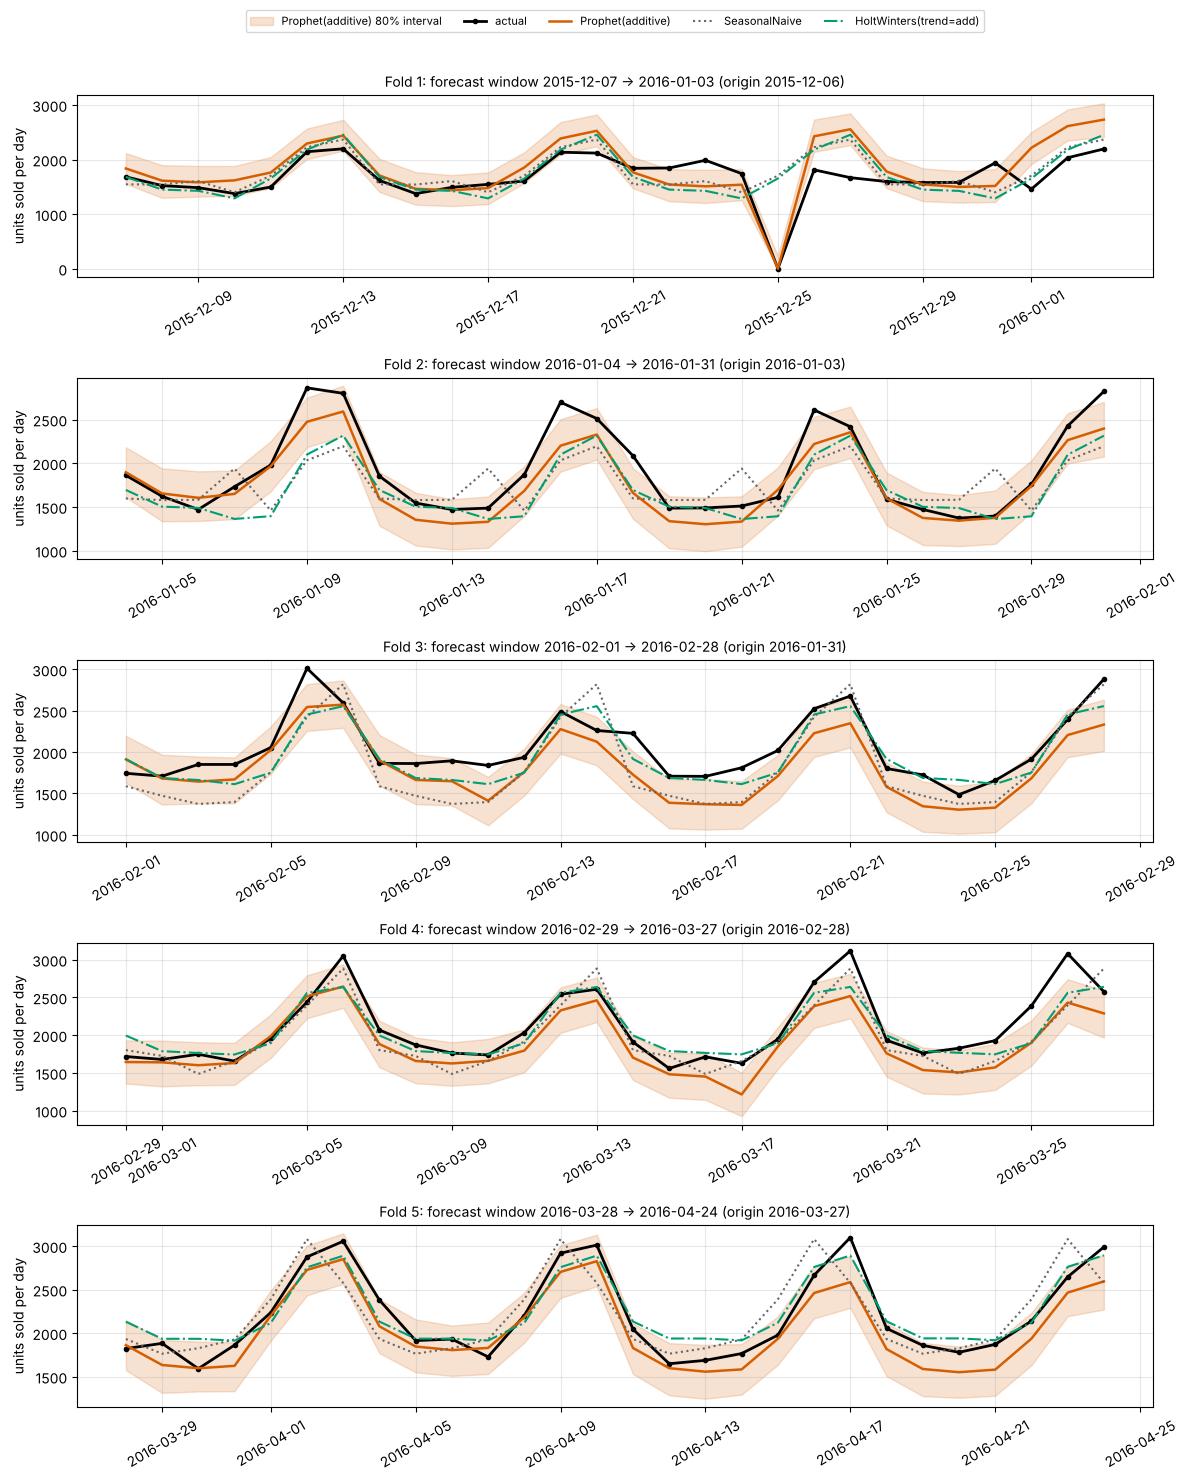

In [10]:
PALETTE = {"SeasonalNaive": "#666666", "ARIMA(6, 1, 1)": "#0072B2", "SARIMA(6, 1, 1)x(0, 0, 2, 7)": "#56B4E9",
           "HoltWinters(trend=add)": "#009E73", "Prophet(additive)": "#D55E00", "Prophet(multiplicative)": "#CC79A7",
           "Prophet(additive,no-regressors)": "#E69F00"}
STYLES = {"SeasonalNaive": ":", "ARIMA(6, 1, 1)": "-.", "SARIMA(6, 1, 1)x(0, 0, 2, 7)": "--", "HoltWinters(trend=add)": "-.",
          "Prophet(additive)": "-", "Prophet(multiplicative)": "--", "Prophet(additive,no-regressors)": ":"}


def save_figure(fig, filename):
    fig.savefig(reports_dir / filename, dpi=150, bbox_inches="tight")


# Figure 1: forecast vs actual with the primary variant's 80 % interval, plus two classical benchmarks.
shown = [m for m in ("SeasonalNaive", "HoltWinters(trend=add)") if m in set(combined["model"])]
fig, axes = plt.subplots(N_FOLDS, 1, figsize=(12, 3.0 * N_FOLDS))
for ax, (_, w) in zip(axes, windows.iterrows()):
    one = saved[(saved["fold"] == w["fold"]) & (saved["model"] == PRIMARY)].sort_values("date")
    ax.fill_between(one["date"], one["lower"], one["upper"], color=PALETTE[PRIMARY], alpha=0.18, label=f"{PRIMARY} {settings.interval_width:.0%} interval")
    ax.plot(one["date"], one["actual"], color="black", linewidth=2.0, marker="o", markersize=3, label="actual")
    ax.plot(one["date"], one["predicted"], color=PALETTE[PRIMARY], linestyle=STYLES[PRIMARY], linewidth=1.8, label=PRIMARY)
    for model in shown:
        m = combined[(combined["fold"] == w["fold"]) & (combined["model"] == model)].sort_values("date")
        ax.plot(m["date"], m["predicted"], linestyle=STYLES[model], color=PALETTE[model], linewidth=1.5, label=model)
    ax.set_title(f"Fold {int(w['fold'])}: forecast window {w['forecast_start'].date()} -> {w['forecast_end'].date()} (origin {w['origin_date'].date()})", fontsize=10)
    ax.set_ylabel("units sold per day")
    ax.tick_params(axis="x", rotation=30)
axes[0].legend(ncol=5, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, 1.5))
fig.tight_layout()
save_figure(fig, p3["prophet_forecast_plot_filename"])
plt.show()

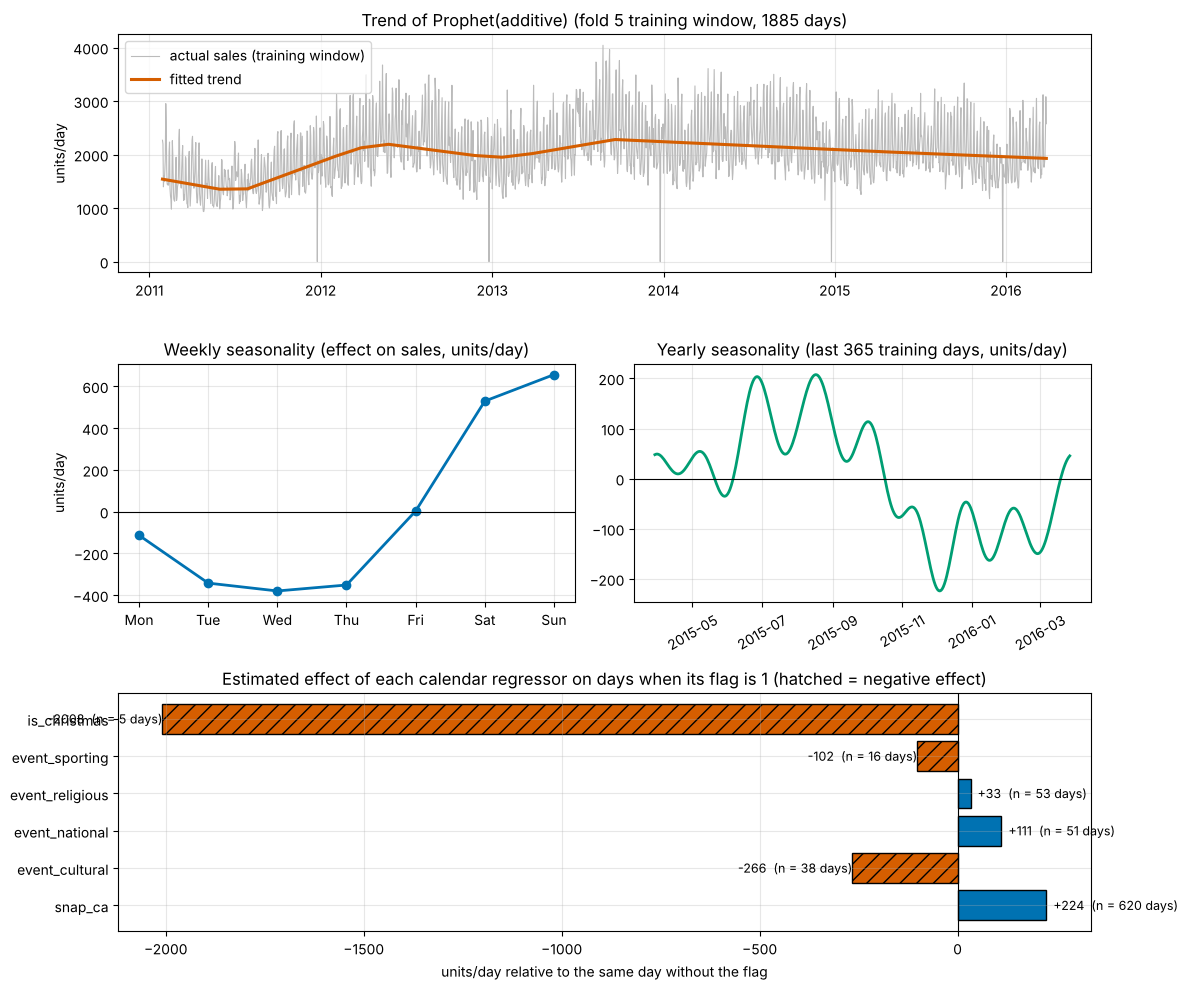

Estimated regressor effects (units/day on flagged days): {'snap_ca': 224.2, 'event_cultural': -265.8, 'event_national': 110.7, 'event_religious': 32.8, 'event_sporting': -101.8, 'is_christmas': -2008.2}


In [11]:
# Figure 2: components of the primary variant fitted on the LAST fold's training window (history days only).
model = runs[PRIMARY]["instances"][-1]
train_dates = series.index[: int(windows.n_train.iloc[-1])]
frame = model.predict_frame(train_dates).assign(ds=lambda f: pd.to_datetime(f["ds"]))
fig = plt.figure(figsize=(12, 10))
grid = fig.add_gridspec(3, 2)

ax = fig.add_subplot(grid[0, :])
ax.plot(train_dates, series.loc[train_dates], color="#bbbbbb", linewidth=0.8, label="actual sales (training window)")
ax.plot(frame["ds"], frame["trend"], color="#D55E00", linewidth=2.2, label="fitted trend")
ax.set_title(f"Trend of {PRIMARY} (fold {N_FOLDS} training window, {len(train_dates)} days)")
ax.set_ylabel("units/day")
ax.legend()

ax = fig.add_subplot(grid[1, 0])
weekly = frame.assign(dow=frame["ds"].dt.dayofweek).groupby("dow")["weekly"].mean()
ax.plot(range(7), weekly.to_numpy(), marker="o", color="#0072B2", linewidth=2)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_xticks(range(7))
ax.set_xticklabels(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"])
ax.set_title("Weekly seasonality (effect on sales, units/day)")
ax.set_ylabel("units/day")

ax = fig.add_subplot(grid[1, 1])
last_year = frame.iloc[-365:]
ax.plot(last_year["ds"], last_year["yearly"], color="#009E73", linewidth=2)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_title("Yearly seasonality (last 365 training days, units/day)")
ax.tick_params(axis="x", rotation=30)

ax = fig.add_subplot(grid[2, :])
effects, counts = [], []
flags = calendar.loc[train_dates, list(EVENT_FLAG_COLUMNS)].reset_index(drop=True)
for name in settings.regressors:
    mask = flags[name].to_numpy() == 1
    effects.append(float(frame.loc[mask, name].mean()) if mask.any() else 0.0)
    counts.append(int(mask.sum()))
bars = ax.barh(range(len(effects)), effects, color=["#D55E00" if e < 0 else "#0072B2" for e in effects], edgecolor="black")
for i, (bar, effect, n) in enumerate(zip(bars, effects, counts)):
    bar.set_hatch("//" if effect < 0 else "")
    ax.text(effect, i, f"  {effect:+.0f}  (n = {n} days)", va="center", ha="left" if effect >= 0 else "right", fontsize=9)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_yticks(range(len(effects)))
ax.set_yticklabels(settings.regressors)
ax.set_title("Estimated effect of each calendar regressor on days when its flag is 1 (hatched = negative effect)")
ax.set_xlabel("units/day relative to the same day without the flag")
fig.tight_layout()
save_figure(fig, p3["prophet_components_plot_filename"])
plt.show()
print("Estimated regressor effects (units/day on flagged days):", {n: round(e, 1) for n, e in zip(settings.regressors, effects)})

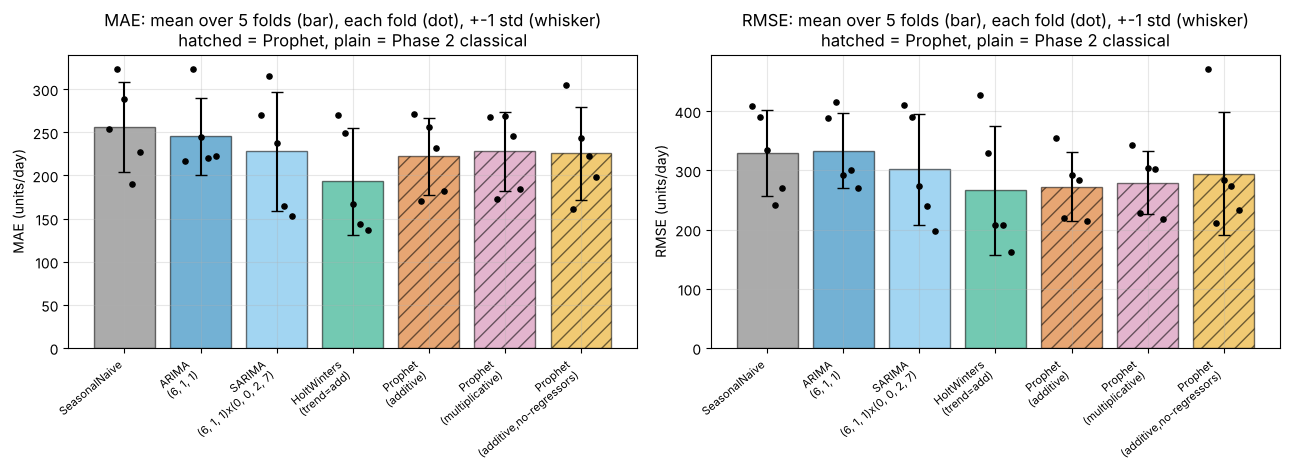

In [12]:
# Figure 3: MAE and RMSE -- mean over folds (bar, hatched = Prophet) with every fold's value (dots) and +-1 std whiskers.
order = CLASSICAL + PROPHET_MODELS
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for ax, metric in zip(axes, ["MAE", "RMSE"]):
    means = fold_metrics.groupby("model")[metric].mean().reindex(order)
    stds = fold_metrics.groupby("model")[metric].std().reindex(order)
    positions = np.arange(len(order))
    bars = ax.bar(positions, means.to_numpy(), yerr=stds.to_numpy(), capsize=4, color=[PALETTE[m] for m in order], alpha=0.55, edgecolor="black")
    for bar, model_name in zip(bars, order):
        if model_name in PROPHET_MODELS:
            bar.set_hatch("//")
    for i, model_name in enumerate(order):
        values = fold_metrics[fold_metrics["model"] == model_name].sort_values("fold")[metric].to_numpy()
        ax.scatter(np.full(len(values), i) + np.linspace(-0.2, 0.2, len(values)), values, color="black", s=14, zorder=4)
    ax.set_xticks(positions)
    ax.set_xticklabels([m.replace("(", "\n(", 1) for m in order], rotation=40, ha="right", fontsize=8)
    ax.set_ylabel(f"{metric} (units/day)")
    ax.set_title(f"{metric}: mean over 5 folds (bar), each fold (dot), +-1 std (whisker)\nhatched = Prophet, plain = Phase 2 classical")
fig.tight_layout()
save_figure(fig, p3["prophet_comparison_plot_filename"])
plt.show()

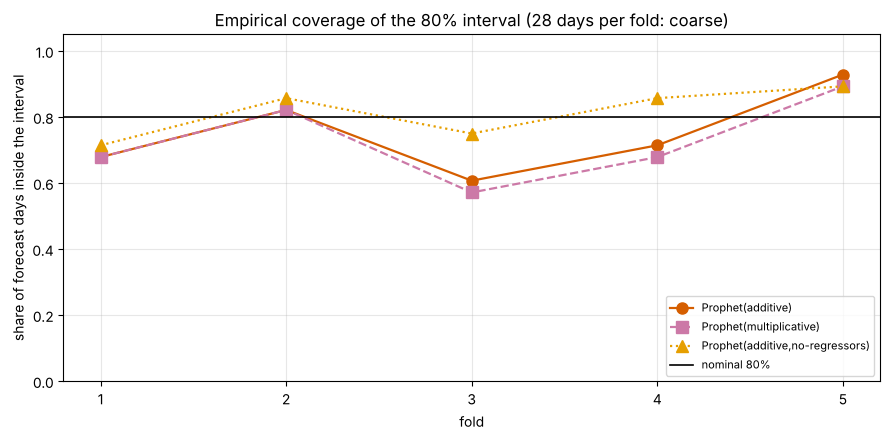

In [13]:
# Figure 4: interval coverage per fold and variant against the nominal level.
fig, ax = plt.subplots(figsize=(9, 4.5))
markers = {"Prophet(additive)": "o", "Prophet(multiplicative)": "s", "Prophet(additive,no-regressors)": "^"}
for name in PROPHET_MODELS:
    one = coverage_by_fold[coverage_by_fold["model"] == name].sort_values("fold")
    ax.plot(one["fold"], one["coverage"], marker=markers[name], linestyle=STYLES[name], color=PALETTE[name], linewidth=1.6, markersize=8, label=name)
ax.axhline(settings.interval_width, color="black", linestyle="-", linewidth=1.2, label=f"nominal {settings.interval_width:.0%}")
ax.set_ylim(0, 1.05)
ax.set_xticks(range(1, N_FOLDS + 1))
ax.set_xlabel("fold")
ax.set_ylabel("share of forecast days inside the interval")
ax.set_title("Empirical coverage of the 80% interval (28 days per fold: coarse)")
ax.legend(fontsize=8, loc="lower right")
fig.tight_layout()
save_figure(fig, p3["prophet_interval_plot_filename"])
plt.show()

## 8. Interpretation (computed from the tables above)

The sentences below are printed by code, so they always match the numbers. They describe **these models on these five
development folds of one aggregate series**; they are not a final ranking, no significance test was run, and the final holdout
was not used.

In [14]:
mae_mean = fold_metrics.groupby("model")["MAE"].mean()
mae_by_fold = fold_metrics.pivot(index="model", columns="fold", values="MAE")
best_overall = mae_mean.idxmin()
best_classical = mae_mean[CLASSICAL].idxmin() if CLASSICAL else None
print(f"Lowest mean MAE among all {len(mae_mean)} models: {best_overall} ({mae_mean[best_overall]:.1f} units/day).")
if best_classical:
    gap = mae_mean[PRIMARY] - mae_mean[best_classical]
    wins = int((mae_by_fold.loc[PRIMARY] < mae_by_fold.loc[best_classical]).sum())
    print(f"Primary variant {PRIMARY} ({mae_mean[PRIMARY]:.1f}) vs best Phase 2 model {best_classical} ({mae_mean[best_classical]:.1f}): "
          f"difference {gap:+.1f} units/day ({100 * gap / mae_mean[best_classical]:+.1f}%); Prophet lower in {wins} of {N_FOLDS} folds.")
if "SeasonalNaive" in mae_mean.index:
    for name in PROPHET_MODELS:
        beats = int((mae_by_fold.loc[name] < mae_by_fold.loc["SeasonalNaive"]).sum())
        print(f"  {name:34s} MAE below Seasonal Naive in {beats} of {N_FOLDS} folds (mean {mae_mean[name]:.1f} vs {mae_mean['SeasonalNaive']:.1f}).")

with_regressors, without = "Prophet(additive)", "Prophet(additive,no-regressors)"
diff = mae_mean[with_regressors] - mae_mean[without]
print(f"\nDo the calendar regressors help? Mean MAE {mae_mean[with_regressors]:.1f} with vs {mae_mean[without]:.1f} without ({diff:+.1f} units/day); "
      f"lower with regressors in {int((mae_by_fold.loc[with_regressors] < mae_by_fold.loc[without]).sum())} of {N_FOLDS} folds.")
fold1_gap = mae_by_fold.loc[with_regressors, 1] - mae_by_fold.loc[without, 1]
print(f"  Fold 1 contains the Christmas closure (zero sales): MAE with vs without regressors differs by {fold1_gap:+.1f} there; in folds 2-5 the mean difference is "
      f"{(mae_by_fold.loc[with_regressors, [2, 3, 4, 5]] - mae_by_fold.loc[without, [2, 3, 4, 5]]).mean():+.1f}.")
add_vs_mult = mae_mean["Prophet(additive)"] - mae_mean["Prophet(multiplicative)"]
print(f"Additive vs multiplicative (both with regressors): {mae_mean['Prophet(additive)']:.1f} vs {mae_mean['Prophet(multiplicative)']:.1f} ({add_vs_mult:+.1f}); "
      f"additive lower in {int((mae_by_fold.loc['Prophet(additive)'] < mae_by_fold.loc['Prophet(multiplicative)']).sum())} of {N_FOLDS} folds.")

print("\nFold-to-fold spread of MAE (max - min):")
for name in CLASSICAL + PROPHET_MODELS:
    print(f"  {name:34s} {mae_by_fold.loc[name].max() - mae_by_fold.loc[name].min():7.1f}")
print("\nInterval coverage (nominal {:.0%}):".format(settings.interval_width), {k: round(v, 3) for k, v in coverage["coverage"].items()})
print("Bias (mean forecast - actual, units/day), averaged over folds:", fold_metrics.groupby("model")["bias"].mean().reindex(PROPHET_MODELS).round(1).to_dict())
print("\nThese are descriptions of five folds. Differences are to be read against fold-to-fold variation; no significance test was performed and none is claimed.")

Lowest mean MAE among all 7 models: HoltWinters(trend=add) (193.3 units/day).
Primary variant Prophet(additive) (222.2) vs best Phase 2 model HoltWinters(trend=add) (193.3): difference +28.9 units/day (+14.9%); Prophet lower in 1 of 5 folds.
  Prophet(additive)                  MAE below Seasonal Naive in 3 of 5 folds (mean 222.2 vs 256.6).
  Prophet(multiplicative)            MAE below Seasonal Naive in 3 of 5 folds (mean 228.0 vs 256.6).
  Prophet(additive,no-regressors)    MAE below Seasonal Naive in 3 of 5 folds (mean 225.9 vs 256.6).

Do the calendar regressors help? Mean MAE 222.2 with vs 225.9 without (-3.6 units/day); lower with regressors in 2 of 5 folds.
  Fold 1 contains the Christmas closure (zero sales): MAE with vs without regressors differs by -32.7 there; in folds 2-5 the mean difference is +3.6.
Additive vs multiplicative (both with regressors): 222.2 vs 228.0 (-5.8); additive lower in 4 of 5 folds.

Fold-to-fold spread of MAE (max - min):
  SeasonalNaive              

## 9. Limitations

* **One series, five folds, 140 forecast days.** Fold-to-fold variation (Section 8) can be as large as gaps between models;
  **no significance test was run**, so no model is declared significantly better.
* **Fixed, untuned settings.** Changepoint and seasonality priors, the number of changepoints and the regressor set are a documented
  starting point from `config.yaml`. Tuning would have to be nested inside each fold's training window; it was not done.
* **Different information sets.** The two regressor variants use calendar facts that the Phase 2 classical models and
  `Prophet(additive,no-regressors)` do not use; compare like with like.
* **Yearly seasonality needs history.** The first folds still have more than five years of daily data, but the yearly term is a
  smooth curve estimated from only five cycles.
* **Interval coverage** is estimated from 28 correlated days per fold: it is descriptive, not a calibration test. The interval
  reflects trend uncertainty and observation noise, not uncertainty about the regressor effects (MAP estimation).
* **MAPE** drops zero-sales days (the Christmas closure) and is not the basis of any statement here.
* **Aggregate series only.** Nothing here says how Prophet behaves on intermittent item-level series; it is not designed for series
  that are mostly zero and is not evaluated on them.
* **Reproducibility.** Point forecasts and the seeded interval are bit-identical on one machine and library version; another operating
  system or Prophet/Stan version can differ in the last digits.
* **Development folds only.** The final 28-day holdout has not been used for training, tuning or selection and is not reported.

## 10. Conclusion

The cell below prints the facts this run established. In words: the notebook builds a leakage-safe Prophet forecaster (history
only, future dates generated from the last history date, calendar regressors from published-in-advance facts, MAP fit, zero-clipped
output), evaluates three pre-declared variants against the Phase 2 models on identical folds, and reports fold-level values,
variation, convergence and interval coverage instead of a single score. It does **not** establish a universal winner, a
significant difference, or how any model will perform on the final holdout.

In [15]:
n_failed = int((~prophet_diagnostics["success"]).sum())
n_nonconv = int((prophet_diagnostics["optimizer_converged"] == False).sum())  # noqa: E712
print(f"Fits: {len(prophet_diagnostics)} ({len(VARIANTS)} variants x {N_FOLDS} folds); failed: {n_failed}; optimiser did not report convergence: {n_nonconv}.")
print(f"Total fitting time {total_seconds:.0f} s (all fits, one CPU thread of the Stan optimiser each).")
print(f"Lowest mean MAE on these five development folds: {best_overall} ({mae_mean[best_overall]:.1f} units/day); primary variant {PRIMARY}: {mae_mean[PRIMARY]:.1f}"
      + (f"; best Phase 2 model {best_classical}: {mae_mean[best_classical]:.1f}." if best_classical else "; no Phase 2 artifact was available."))
print("Status: development folds only; no significance test; final holdout (2016-04-25 to 2016-05-22) not used in this notebook.")
print(f"Saved: {p3['prophet_forecasts_filename']}, {p3['prophet_metrics_filename']}, {p3['prophet_diagnostics_filename']}, "
      f"{p3['prophet_metadata_filename']} and four figures in reports/phase3/.")

Fits: 15 (3 variants x 5 folds); failed: 0; optimiser did not report convergence: 0.
Total fitting time 10 s (all fits, one CPU thread of the Stan optimiser each).
Lowest mean MAE on these five development folds: HoltWinters(trend=add) (193.3 units/day); primary variant Prophet(additive): 222.2; best Phase 2 model HoltWinters(trend=add): 193.3.
Status: development folds only; no significance test; final holdout (2016-04-25 to 2016-05-22) not used in this notebook.
Saved: prophet_backtest_forecasts.csv, prophet_backtest_metrics.csv, prophet_fit_diagnostics.csv, prophet_run_metadata.json and four figures in reports/phase3/.


## Reproduce

From the project root (PowerShell):

```powershell
python -m pip install -r requirements-phase3.txt          # once: adds torch, prophet, streamlit, plotly
python -m pytest tests/models/test_prophet_model.py       # fast unit tests (about 10 seconds)
python -m jupyter nbconvert --to notebook --execute --inplace notebooks/08_prophet.ipynb
```

The settings live in `config.yaml` (section `prophet`); the model is `src/models/prophet_model.py`.